# Datasets, counterfactual branching, TTA streams
* `run_episode` / `write_episode` write the lab's real-data layout (parquet + mp4 + annotations)
* `get_state` / `set_state` are bit-exact: branch K action chunks from one state (latent-steering RQ1)
* `streams.make_stream` builds continual-TTA protocols with ground-truth regime labels

In [1]:
# Setup cell, inlined into every notebook by notebooks/build.py.
# Locally: finds the repo. On a Colab runtime (also VS Code connected to Colab), where the code is not
# on the VM: clones ROBOGYM_REPO (default: the public repo), pip-installs it, sets MUJOCO_GL=egl and
# keeps data/ + runs/ on Drive when it is mounted.
import os, pathlib, subprocess, sys

DEFAULT_REPO = "https://github.com/carlo-scr/RoboGym.git"
ROBOGYM_REPO = os.environ.get("ROBOGYM_REPO") or DEFAULT_REPO
USE_DRIVE = os.environ.get("ROBOGYM_DRIVE", "1") == "1"
IN_COLAB = "google.colab" in sys.modules or "COLAB_RELEASE_TAG" in os.environ
if IN_COLAB:
    os.environ.setdefault("OPENBLAS_NUM_THREADS", "1")
    os.environ.setdefault("MUJOCO_GL", "egl")
    os.environ.setdefault("PYOPENGL_PLATFORM", "egl")
    _icd = pathlib.Path("/usr/share/glvnd/egl_vendor.d/10_nvidia.json")
    if subprocess.run(["nvidia-smi"], capture_output=True).returncode == 0 and not _icd.exists():
        _icd.parent.mkdir(parents=True, exist_ok=True)
        _icd.write_text('{"file_format_version": "1.0.0", "ICD": {"library_path": "libEGL_nvidia.so.0"}}\n')
    CODE = pathlib.Path("/content/RoboGym")
    DRIVE = pathlib.Path("/content/drive/MyDrive")
    if (CODE / ".git").exists():
        subprocess.run(["git", "-C", str(CODE), "pull", "-q"])
    if not (CODE / "robogym").exists():
        subprocess.run(["git", "clone", "-q", ROBOGYM_REPO, str(CODE)], check=True)
    if USE_DRIVE and not DRIVE.exists():
        try:
            from google.colab import drive

            drive.mount("/content/drive")
        except Exception as e:  # noqa: BLE001
            print("Drive not mounted:", e)
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-e", f"{CODE}[gym]"], check=True)
    if DRIVE.exists():
        for d in ("data", "runs"):
            tgt = DRIVE / "robogym_runs" / d
            tgt.mkdir(parents=True, exist_ok=True)
            link = CODE / d
            if not link.is_symlink():
                subprocess.run(["rm", "-rf", str(link)])
                link.symlink_to(tgt)
    os.chdir(CODE)
ROOT = pathlib.Path.cwd()
while not (ROOT / "robogym").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
if sys.platform.startswith("linux") and not os.environ.get("DISPLAY"):
    os.environ.setdefault("MUJOCO_GL", "egl")
print("ROOT:", ROOT, "| colab:", IN_COLAB)

ROOT: /Users/carloschreiber/Desktop/Uni/Research/Humanoid (Watney)/RoboGym | colab: False


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from robogym.env import RoboGymEnv
from robogym.datagen import EpisodeSpec, run_episode, write_episode, load_episode, restore, build_episode
from robogym.research import branch_outcomes, monitor_labels
from robogym.streams import make_stream, regime_table
from robogym.tools import run_until

env = RoboGymEnv("lego")
OUT = Path("data/demo_lego")

## Write, load, restore

In [3]:
ep = run_episode(env, EpisodeSpec(seed=2, dart=0.002), cameras=["right_wrist", "front"])
path = write_episode(ep, OUT / "ep_000002", fps=env.cfg.sim.control_hz, cfg=env.cfg)
E = load_episode(path)
print(E["df"].columns.tolist())
print("outcome:", E["annotations"]["outcome"], "| horizon:", E["annotations"]["horizon"], "| stage times:", E["annotations"]["stage_times_s"])
k = len(E["df"]) // 2
restore(env, E, k)
st = np.stack(E["df"]["observation.state"].values)
dev = 0.0
for j in range(k, len(st) - 1):
    env.step(E["actions64"][j])
    dev = max(dev, float(np.abs(env.observe() - st[j + 1]).max()))
print("restore + replay max state deviation:", dev)

['timestamp', 'frame_index', 'observation.state', 'action', 'action.ee_target', 'action.expert', 'task.features', 'priv.phase', 'priv.subgoal', 'priv.stage', 'priv.progress', 'priv.grasped_k', 'priv.regime_id', 'priv.n_done', 'priv.r_xy', 'priv.r_z', 'priv.r_yaw', 'priv.tilt', 'priv.snapped']
outcome: success | horizon: 4 | stage times: {'reach_0': 0.0, 'grasp_0': 1.7, 'carry_0': 2.15, 'align_0': 3.05, 'press_0': 3.15, 'reach_1': 4.7, 'grasp_1': 7.45, 'carry_1': 7.9, 'align_1': 9.1, 'press_1': 9.25, 'reach_2': 10.75, 'grasp_2': 13.45, 'carry_2': 13.9, 'align_2': 15.0, 'press_2': 15.05, 'reach_3': 16.6, 'grasp_3': 19.5, 'carry_3': 19.95, 'align_3': 21.2, 'press_3': 21.25, 'done': 22.8}


restore + replay max state deviation: 0.0


## Monitor labels from a recorded failure

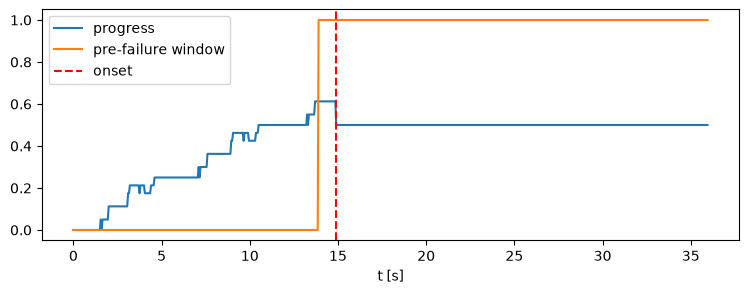

In [4]:
ep_f = run_episode(env, EpisodeSpec(seed=3, category="known_failure", failure="drop", severity=0.8), cameras=[], save_states=False)
write_episode(ep_f, OUT / "ep_fail", fps=env.cfg.sim.control_hz, cfg=env.cfg)
Ef = load_episode(OUT / "ep_fail")
lab = monitor_labels(Ef["df"], Ef["annotations"], lead_s=1.0)
t = Ef["df"]["timestamp"].values * 1e-9
plt.figure(figsize=(9, 3))
plt.plot(t, lab["progress"], label="progress")
plt.plot(t, lab["pre_failure"], label="pre-failure window")
plt.axvline(lab["onset_s"], color="r", ls="--", label="onset")
plt.legend(); plt.xlabel("t [s]"); plt.show()

## Counterfactual branching (the RQ1 oracle mechanism)
Snapshot while carrying the first brick, then execute 6 candidate chunks (hold + random lateral drift)
and let the expert-free "hold" continuation finish. Differences between branches come from the chunks alone.

In [5]:
sc, _, ex = build_episode(env, EpisodeSpec(seed=7))
run_until(env, ex, "carry", subgoal=0)
state = env.get_state()
rng = np.random.default_rng(0)
hold = np.zeros(8); hold[6] = 1.0
chunks = [np.repeat(hold[None], 8, 0) + np.concatenate([rng.normal(0, s, 3), np.zeros(5)]) for s in (0, 0, 0.003, 0.006, 0.01, 0.015)]
res = branch_outcomes(env, state, chunks, lambda e: hold, max_s=env.time + 2.0)
pd.DataFrame(res)

,success,progress,stage,duration_s,unstable
0,False,0.1125,carry_0,4.25,False
1,False,0.1125,carry_0,4.25,False
2,False,0.1125,carry_0,4.25,False
3,False,0.1125,carry_0,4.25,False
4,False,0.1125,carry_0,4.25,False
5,False,0.1125,carry_0,4.25,False


## TTA stream protocols

In [6]:
for name in ("sudden", "gradual", "recurring", "mixed", "in_episode"):
    specs = make_stream(name, 12, seed0=0)
    print(f"{name:11s}", [r[1] for r in regime_table(specs)])

sudden      [0, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1]
gradual     [0, 1, 1, 2, 2, 2, 3, 3, 3, 4, 4, 4]
recurring   [0, 0, 0, 0, 0, 1, 1, 1, 1, 1, 0, 0]
mixed       [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 4, 4]
in_episode  [1, 4, 3, 2, 3, 3, 2, 3, 3, 1, 1, 1]
